In [1]:
import numpy as np
import pandas as pd
import itertools
import scipy.stats
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import MultipleLocator
from scipy.stats.mstats import zscore
import matplotlib.gridspec as gridspec
import statsmodels.api as sm
from tqdm import tqdm
import re
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['axes.linewidth'] = 0.8  # Thin spines
plt.rcParams['xtick.major.width'] = 0.8
plt.rcParams['ytick.major.width'] = 0.8
plt.rcParams['xtick.direction'] = 'out'
plt.rcParams['ytick.direction'] = 'out'

# Load

In [2]:
def process_reg(reg1):
    reg1 = reg1.drop([0],axis=0)
    del reg1['1']
    reg1.index = reg1['Dependent Var.:'].values
    del reg1['Dependent Var.:']
    reg1 = reg1.T
    reg1['Variable'] = reg1.index
    return reg1
def extract_reg_info(reg_string):
    if not reg_string or reg_string.strip() == '':
        return {'coef': 'none', 'se': 'none', 'stars': 'none'}

    s = reg_string.strip()
    coef = None
    se = None
    stars = ' '

    # 1. Extract Standard Error (SE)
    se_match = re.search(r'\((.*?)\)', s)
    if se_match:
        se_value = se_match.group(1).strip()
        if se_value.upper() == 'NA':
            se = 'NA'
        else:
            try:
                se = float(se_value)
            except ValueError:
                # Should not happen with typical reg output
                se = 'error' 
        
        # Remove the SE part from the string for subsequent coefficient extraction
        s_without_se = s[:s.find('(')].strip()
    else:
        # If no parentheses are found, assume the entire string is the coefficient part
        s_without_se = s
        se = 'none' # No SE found

    # 2. Extract Significance Stars
    if '***' in s_without_se:
        stars = '***'
    elif '**' in s_without_se:
        stars = '**'
    elif '*' in s_without_se:
        stars = '*'
        
    # Remove stars to get the clean coefficient string
    s_no_stars = s_without_se.replace('***', '').replace('**', '').replace('*', '').strip()

    # 3. Extract Coefficient (and handle the stray period)
    # This regex specifically looks for a coefficient which can be:
    # - Optional sign (+/-)
    # - Digits
    # - Optional decimal part
    # It accounts for the period that seems to be a common issue (e.g., '-0.0307.')
    # and only extracts the number itself.
    coef_match = re.search(r'([-+]?\s*\d*\.?\d+)', s_no_stars)
    
    if coef_match:
        try:
            # The found group will contain the number (e.g., '0.0307')
            coef = float(coef_match.group(1).strip())
        except ValueError:
            # Fallback if float conversion still fails (e.g., empty string after cleaning)
            coef = 'error' 
    else:
        # If no number is found at all
        coef = 'error'

    return {'coef': coef, 'ci': se*1.96, 'stars': stars}

In [3]:
df = pd.read_parquet('Data/paper_data_control.parquet')
df1 = df[df['nau']>1].reset_index(drop=True)

In [4]:
df.columns

Index(['PaperID', 'is_orange', 'Year', 'FieldID', 'DomainID', 'SourceID',
       'nref', 'nau', 'citpct', 'CD', 'is_oa', 'fund', 'Productivity_1st',
       'TC_1st', 'age_1st', 'Female_1st', 'Productivity_last', 'TC_last',
       'age_last', 'Female_last', 'n_institutions', 'n_countries',
       'Inst_entropy', 'Country_entropy', 'n_Field', 'Field_entropy',
       'Age_mean', 'Age_entropy', 'distance', 'Gender_P', 'Gender_entropy'],
      dtype='object')

In [5]:
reg1 = process_reg(pd.read_csv('Data/Reg_results/reg_3_papers.csv',header=1))
reg2 = process_reg(pd.read_csv('Data/Reg_results/reg_4_papers.csv',header=1))
reg3 = process_reg(pd.read_csv('Data/Reg_results/reg_2_papers.csv',header=1))
reg1[['coef1', 'ci1', 'star1']] = reg1['is_orange'].apply(lambda x: extract_reg_info(x)).apply(pd.Series)
reg2[['coef1', 'ci1', 'star1']] = reg2['is_orange'].apply(lambda x: extract_reg_info(x)).apply(pd.Series)
reg3[['coef1', 'ci1', 'star1']] = reg3['is_orange'].apply(lambda x: extract_reg_info(x)).apply(pd.Series)

variable_list = ['distance', 'Country_entropy', 'Inst_entropy', 'Field_entropy', 'Age_entropy', 'Gender_entropy']
y_labels = ['Geo distance','Country diversity','Institution diversity','Field diversity','Age diversity','Gender diversity']
reg1 = reg1.reindex(variable_list)
reg2 = reg2.reindex(variable_list)

variable_list_ = ['TC_last','Productivity_last','age_last','Female_last','TC_1st','Productivity_1st','age_1st','Female_1st']
y_labels_ = ['Last author\ncitations','Last author\nproductivity','Last author\ncareer age','Last author\n is female','First author\ncitations','First author\nproductivity','First author\ncareer age ','First author\n is female']
reg3 = reg3.reindex(variable_list_)

In [6]:
df1['P_Field'] = df1['n_Field'].apply(lambda x:1 if x>1 else 0)
df1['P_institutions'] = df1['n_institutions'].apply(lambda x:1 if x>1 else 0)
df1['P_countries'] = df1['n_countries'].apply(lambda x:1 if x>1 else 0)

In [7]:
df['CD_'] = df['CD'].apply(lambda x: np.nan if pd.isna(x) else (1 if x > 0 else 0))

# Draw functions

In [8]:
def get_whisker_max(data):
    """Calculates the upper whisker position (Q3 + 1.5*IQR), capped at max data point."""
    Q1 = np.percentile(data, 25)
    Q3 = np.percentile(data, 75)
    IQR = Q3 - Q1
    whisker_pos = Q3 + 1.5 * IQR
    # Use np.max(data) for the absolute maximum value
    return np.min([whisker_pos, np.max(data)]) 

In [9]:
def draw_box(ax,y_label,group_0, group_1):
    data_to_plot = [group_0, group_1]
    t_stat, p_value = scipy.stats.ttest_ind(group_0, group_1, equal_var=False)
    mean_0 = np.mean(group_0)
    mean_1 = np.mean(group_1)
    percent_diff = ((mean_1 - mean_0) / mean_0) * 100
    max_whisker_0 = get_whisker_max(group_0)
    max_whisker_1 = get_whisker_max(group_1)
    y_max_eff = np.max([max_whisker_0, max_whisker_1])

    color0 = 'tab:blue'
    color1 = 'tab:red'
    colors = [color0, color1]
    bp = ax.boxplot(data_to_plot, 
        tick_labels=[f'Control\npapers\nN={len(group_0):,}', f'Upstream\npapers\nN={len(group_1):,}'],
        vert=True,patch_artist=True,showfliers=False,
        medianprops=dict(color='black', linewidth=1.5),whiskerprops=dict(color='black', linewidth=0.8),
        capprops=dict(color='black', linewidth=0.8),boxprops=dict(linewidth=0.8, linestyle='-'))

    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7) # Slightly opaque for a professional look

    h_bracket = (y_max_eff * 0.05) # Height for the bracket to lift off the max whisker
    h_line = (y_max_eff * 0.01) # Small vertical line segment
    h_text = (y_max_eff * 0.04) # Vertical distance for text from the bracket line
    y_ann = y_max_eff + h_bracket # Annotation bar top y-position
    x1, x2 = 1, 2
    ax.plot([x1, x1, x2, x2], [y_ann, y_ann + h_line, y_ann + h_line, y_ann], lw=0.8, c='k')
    p_text_full = f'P = {p_value:.3f}' if p_value >= 0.001 else 'p < 0.001'

    ax.text((x1 + x2) * 0.5, y_ann + h_line + h_text, 
        rf'$\Delta$ {f'{percent_diff:+.1f}%'}'+'\n'+f'{p_text_full}', 
        ha='center', va='bottom', fontsize=11)
    ax.tick_params(axis='x', labelsize=11)
    ax.tick_params(axis='y', labelsize=11)
    ax.set_ylabel(y_label,fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

In [10]:
def draw_bar(ax, y_label, group_0, group_1):
    data_to_plot = [group_0, group_1]
    
    # Calculate means and standard errors (or standard deviations) for the bar plot
    mean_0 = np.mean(group_0)
    mean_1 = np.mean(group_1)

    means = [mean_0, mean_1]
    
    # Calculate statistics for the annotation
    percent_diff = ((mean_1 - mean_0) / mean_0) * 100
    
    # Define colors and x-positions
    x_pos = np.arange(len(means)) 
    color0 = 'tab:blue'
    color1 = 'tab:red'
    colors = [color0, color1]
    labels = [f'Control\npapers\nN={len(group_0):,}', f'Upstream\npapers\nN={len(group_1):,}']

    # Draw the bar plot
    ax.bar(x_pos, means, align='center', alpha=0.7, color=colors, width=0.3)

    # Calculate y-maximum for annotation placement
    # Using the highest point of the bar + error bar for annotation placement
    max_y_value = np.max([mean_0, mean_1])
    
    # Annotation for percentage difference
    h_bracket = (max_y_value * 0.05)  # Height for the bracket to lift off the max error bar
    h_line = (max_y_value * 0.01)     # Small vertical line segment
    h_text = (max_y_value * 0.02)     # Vertical distance for text from the bracket line
    y_ann = max_y_value + h_bracket   # Annotation bar top y-position
    x1, x2 = x_pos[0], x_pos[1]
    
    # Draw the bracket
    ax.plot([x1, x1, x2, x2], [y_ann, y_ann + h_line, y_ann + h_line, y_ann], lw=0.8, c='k')
    
    # Draw the percentage difference text (t-stat is not used in the text, so we calculate p-value only if needed)
    # The requirement was to remove P-values, so only the percentage difference remains.
    ax.text((x1 + x2) * 0.5, y_ann + h_line + h_text, 
            rf'$\Delta$ {f'{percent_diff:+.1f}%'}', 
            ha='center', va='bottom', fontsize=11)
            
    # Set tick labels and style
    ax.set_xticks(x_pos)
    ax.set_xticklabels(labels)
    ax.tick_params(axis='x', labelsize=11)
    ax.tick_params(axis='y', labelsize=11)
    ax.set_ylabel(y_label, fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylim(bottom=0) # Ensure y-axis starts at zero for a bar plot
    
    # Adjust plot limits to make room for the annotation
    # Ensure there is enough space above the highest annotation
    ax.set_ylim(top=y_ann + h_line + h_text + (max_y_value * 0.05))

In [11]:
def draw_a(ax):
        number_year = df[df['is_orange'] == 1].groupby('Year').size().reset_index(name='Count')
        number_year = number_year[number_year['Year'].isin(range(1970, 2022))]

        number_year_field = df[df['is_orange'] == 1].groupby(['Year', 'DomainID']).size().reset_index(name='Count')
        number_year_field = number_year_field[number_year_field['Year'].isin(range(1970, 2022))]

        # Data for the main line plot (ALL 4 Domains: 1, 2, 3, 4)
        data_1 = number_year_field[number_year_field['DomainID'] == 1] # Life Sciences
        data_2 = number_year_field[number_year_field['DomainID'] == 2] # Social Sciences
        data_3 = number_year_field[number_year_field['DomainID'] == 3] # Physical Sciences
        data_4 = number_year_field[number_year_field['DomainID'] == 4] # Health Sciences

        # Data preparation for the inset stack plot (Domains 1, 2, 3, 4)
        selected_domains = [1, 2, 3, 4]
        stack_data_counts = number_year_field[number_year_field['DomainID'].isin(selected_domains)].copy()

        # Unstack data to have DomainID as columns (1, 2, 3, 4)
        stack_data = stack_data_counts.groupby(['Year', 'DomainID'])['Count'].sum().unstack(fill_value=0).reset_index()

        # Calculate the total count *only* for the selected domains (1, 2, 3, 4) for the 100% normalization
        total_counts_selected = stack_data_counts.groupby('Year')['Count'].sum().reset_index(name='Selected_Total_Count')
        stack_data = pd.merge(stack_data, total_counts_selected, on='Year')

        # Calculate percentages for each of the four categories
        stack_data['Perc_1'] = (stack_data[1] / stack_data['Selected_Total_Count']) * 100 # Life Sciences
        stack_data['Perc_2'] = (stack_data[2] / stack_data['Selected_Total_Count']) * 100 # Social Sciences
        stack_data['Perc_3'] = (stack_data[3] / stack_data['Selected_Total_Count']) * 100 # Physical Sciences
        stack_data['Perc_4'] = (stack_data[4] / stack_data['Selected_Total_Count']) * 100 # Health Sciences

        years_stack = stack_data['Year'].values
        perc_1 = stack_data['Perc_1'].values
        perc_2 = stack_data['Perc_2'].values
        perc_3 = stack_data['Perc_3'].values
        perc_4 = stack_data['Perc_4'].values
        N = len(years_stack)

        y_2_bottom = np.zeros(N)
        y_2_top = perc_2
        y_3_bottom = y_2_top
        y_3_top = y_3_bottom + perc_3
        y_4_bottom = y_3_top
        y_4_top = y_4_bottom + perc_4
        y_1_bottom = y_4_top
        y_1_top = y_1_bottom + perc_1

        # Domain 1 (Life Sciences) line (green dashed)
        ax.plot(data_1['Year'].values, data_1['Count'].values,
                color='tab:green', linestyle='--', label='Life Sciences (1)')

        # Domain 2 (Social Sciences) line (orange dotted) - NEW
        ax.plot(data_2['Year'].values, data_2['Count'].values,
                color='tab:orange', linestyle=':', label='Social Sciences (2)')

        # Domain 3 (Physical Sciences) line (blue dotted) - NEW
        ax.plot(data_3['Year'].values, data_3['Count'].values,
                color='tab:blue', linestyle=':', label='Physical Sciences (3)')

        # Domain 4 (Health Sciences) line (purple dash-dot)
        ax.plot(data_4['Year'].values, data_4['Count'].values,
                color='tab:purple', linestyle='-.', label='Health Sciences (4)')


        ax.set_xlabel('Year')
        ax.set_ylabel('N (Upstream papers)', labelpad=10)
        ax.set_xlim(1970, 2021)
        # ax.legend(frameon=False, loc='lower left') # Optional legend, uncomment if needed
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)

        # Text annotations for the two largest domains (as they were originally)
        ax.text(2000, 850, 'Life Sciences',
                fontsize=11, color='tab:green', ha='left', va='center')
        ax.text(2010, 1200, 'Health Sciences',
                fontsize=11, color='tab:purple', ha='left', va='center')
        ax.text(1995, 230, 'Physical Sciences',
                fontsize=11, color='tab:blue', ha='left', va='center')
        ax.text(2000, 0, 'Social Sciences',
                fontsize=11, color='tab:orange', ha='left', va='center')
        # --- Inset Plotting Commands ---
        ax_inset = fig.add_axes([0.15, 0.8, 0.1, 0.08])

        # Stacked area plot (4 layers)
        ax_inset.fill_between(years_stack, y_2_bottom, y_2_top,
                        color='tab:orange', alpha=0.5, label='Social Sciences (2)') # Bottom
        ax_inset.fill_between(years_stack, y_3_bottom, y_3_top,
                        color='tab:blue', alpha=0.6, label='Physical Sciences (3)')
        ax_inset.fill_between(years_stack, y_4_bottom, y_4_top,
                        color='tab:purple', alpha=0.7, label='Health Sciences (4)')
        ax_inset.fill_between(years_stack, y_1_bottom, y_1_top,
                        color='tab:green', alpha=0.7, label='Life Sciences (1)') # Top


        ax_inset.set_title('Field section (%)', fontsize=11)
        ax_inset.set_xlim(1970, 2021)
        ax_inset.set_ylim(0, 100)
        ax_inset.set_xticks(np.arange(1970, 2022, 20))
        ax_inset.set_yticks(np.arange(0, 101, 50))
        ax_inset.tick_params(axis='both', which='major', labelsize=11)

        ax_inset.spines['right'].set_visible(False)
        ax_inset.spines['top'].set_visible(False)

        plt.tight_layout()

In [12]:
def draw_reg_1(ax):
    plot_info = {
        'Model 1': {'data': reg1, 'y_offset': -0.15, 'dot_color': 'k', 'whisker_color': 'k', 'marker': 'o', 'label': 'without author FE'},
        'Model 2': {'data': reg2, 'y_offset': 0.15, 'dot_color': '#A93226', 'whisker_color': '#A93226', 'marker': 's', 'label': 'with author FE'}}

    variable_order = reg1.index.tolist()
    y_pos = np.arange(len(variable_order))
    y_map = {var: i for i, var in enumerate(variable_order)}

    for model_name, info in plot_info.items():
        data = info['data']
        y_coords = data.index.map(y_map) + info['y_offset']
        ax.errorbar(x=data['coef1'], y=y_coords,xerr=data['ci1'], fmt=info['marker'],
            capsize=4,label=info['label'], color=info['dot_color'], ecolor=info['whisker_color'], elinewidth=1, markersize=5)
        if model_name == 'Model 2':
            for i, row in data.iterrows():
                ax.text(x=row['coef1'],y=y_map[i]+0.22, s='coef = '+f"{row['coef1']:.2f}{row['star1']}",
                    fontsize=11,color=info['dot_color'],ha='center',va='bottom')
    ax.axvline(x=0, color='grey', linestyle='--', linewidth=1, alpha=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(y_labels, fontsize=11)
    ax.set_title('Estimated coefficient (95% CI)', fontsize=11)
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0) # Hide y ticks
    ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2)
    ax.set_xlim(-0.03,0.22)

In [13]:
def draw_reg_2(ax):
    info = {'data': reg3, 'y_offset': 0, 'dot_color': 'k', 'whisker_color': 'k', 'marker': 'o', 'label': 'without author FE'}

    variable_order = reg3.index.tolist()
    y_pos = np.arange(len(variable_order))
    y_map = {var: i for i, var in enumerate(variable_order)}
    data = info['data']
    y_coords = data.index.map(y_map) + info['y_offset']
    ax.errorbar(x=data['coef1'], y=y_coords,xerr=data['ci1'], fmt=info['marker'],
    capsize=4,color=info['dot_color'], ecolor=info['whisker_color'], elinewidth=1, markersize=5)
    for i, row in data.iterrows():
        ax.text(x=row['coef1'],y=y_map[i]+0.12, s='coef = '+f"{row['coef1']:.2f}{row['star1']}",
            fontsize=11,color=info['dot_color'],ha='center',va='bottom')
    ax.axvline(x=0, color='grey', linestyle='--', linewidth=1, alpha=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(y_labels_, fontsize=11)
    ax.set_title('Estimated coefficient (95% CI)', fontsize=11)
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False) # Optional: cleaner look
    ax.tick_params(axis='y', length=0) # Hide y ticks

# Final figure

In [14]:
df[df['Productivity_1st']>500]

,PaperID,is_orange,Year,FieldID,DomainID,SourceID,nref,nau,citpct,CD,...,Inst_entropy,Country_entropy,n_Field,Field_entropy,Age_mean,Age_entropy,distance,Gender_P,Gender_entropy,CD_
3695,2049888408,1,1979,16.0,3.0,205050996,0,4,99.746257,NaN,...,NaN,NaN,1.0,0.000000,8.500000,1.039721,NaN,0.00,0.000000,NaN
3977,2003862801,1,1980,16.0,3.0,205050996,0,3,98.522600,NaN,...,NaN,NaN,1.0,0.000000,23.666667,1.098612,NaN,0.00,0.000000,NaN
5682,4252413852,1,1983,32.0,2.0,31827231,0,1,0.000000,NaN,...,NaN,NaN,1.0,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN
6282,2034271481,1,1984,27.0,4.0,67514239,0,3,95.627298,NaN,...,0.000000,0.000000,1.0,0.000000,31.500000,0.693147,NaN,0.00,0.000000,NaN
6316,2952654636,1,1984,16.0,3.0,205050996,0,3,40.549431,NaN,...,NaN,NaN,2.0,0.636514,36.333333,0.636514,NaN,0.00,0.000000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
352879,3124121244,0,2021,27.0,4.0,153913659,116,8,99.212111,-0.003805,...,1.255482,0.661563,1.0,0.000000,23.125000,1.386294,1234.733820,0.25,0.562335,0.0
353058,3187503536,0,2021,32.0,2.0,1502225,108,4,87.336758,-0.002946,...,0.562335,0.562335,2.0,0.562335,32.000000,1.039721,10286.980200,0.25,0.562335,0.0
353089,4303423685,0,2022,27.0,4.0,49861241,0,1,0.000000,NaN,...,NaN,NaN,1.0,0.000000,40.000000,0.000000,NaN,0.00,0.000000,NaN
353092,4295800729,0,2022,27.0,4.0,49861241,0,1,0.000000,NaN,...,NaN,NaN,1.0,0.000000,17.000000,0.000000,NaN,0.00,0.000000,NaN


C:\Users\nd\AppData\Local\Temp\ipykernel_11660\1506306732.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


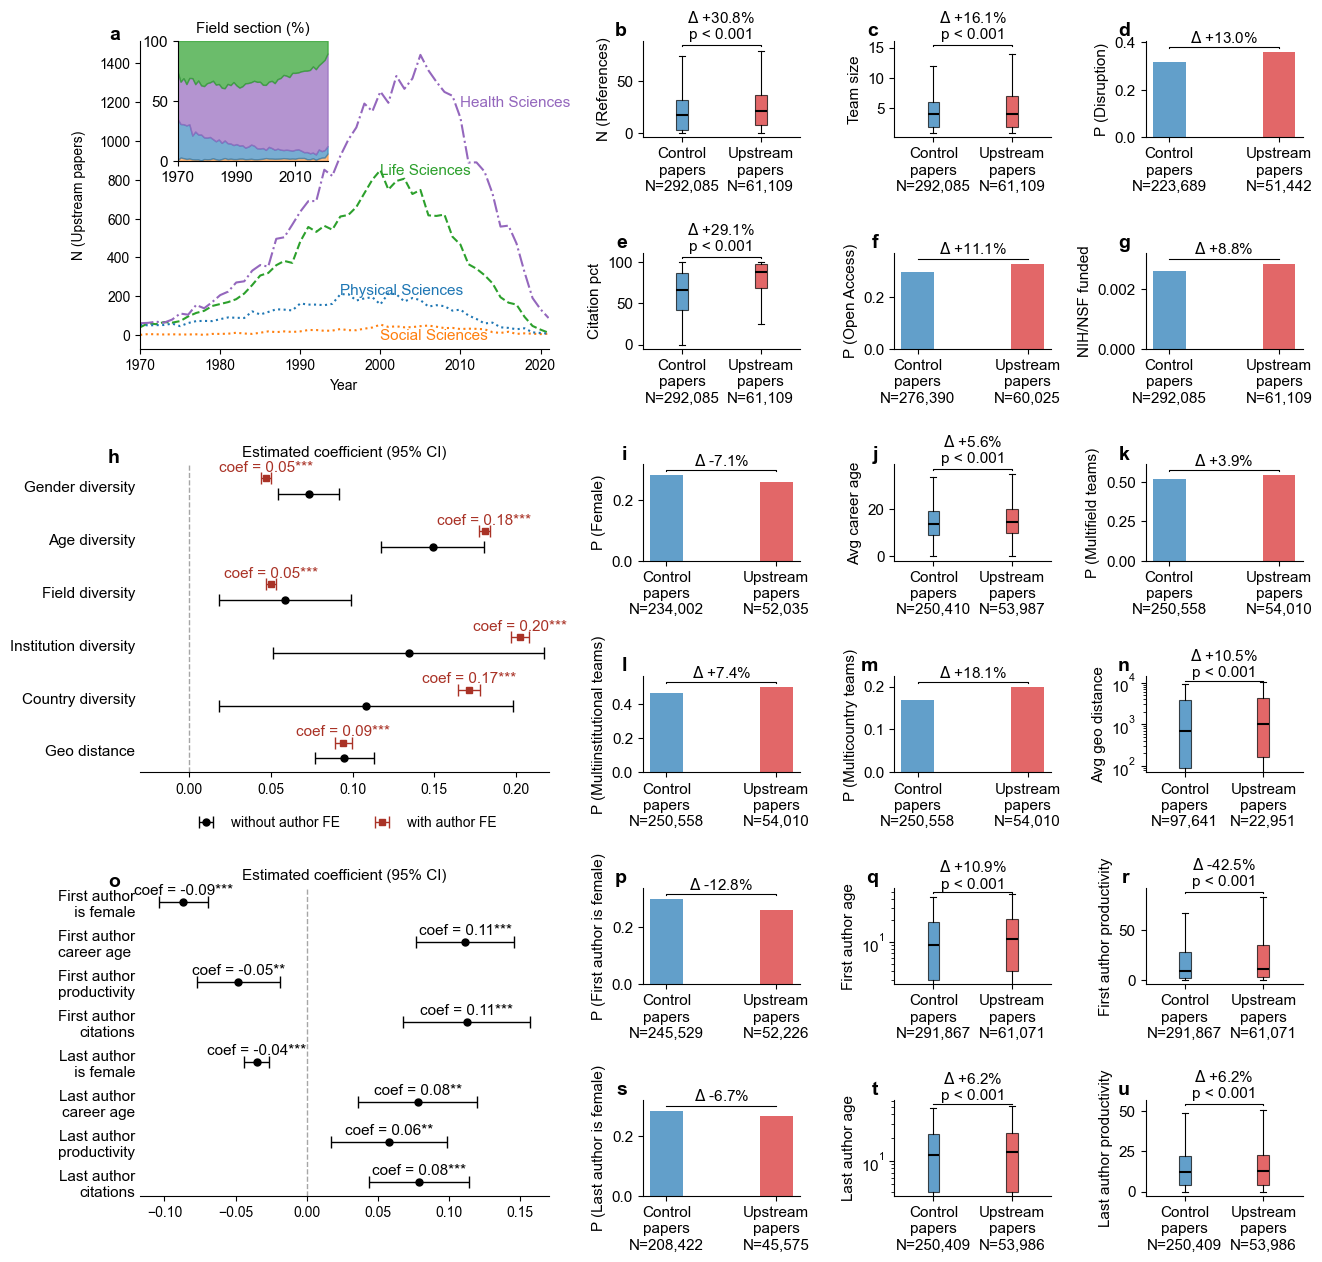

In [15]:
fig = plt.figure(figsize=(15, 15)) 
gs_master = gridspec.GridSpec(nrows=6, ncols=5, figure=fig, wspace=0.6,hspace=1.2)

# --- Block 1: a-f ---
group_lst1_a = ['nref', 'nau', 'CD_', 'citpct', 'is_oa', 'fund']
y_labels_b = {'nref': 'N (References)','nau': 'Team size', 'CD_':'P (Disruption)','citpct': 'Citation pct','is_oa': 'P (Open Access)','fund': 'NIH/NSF funded'}
box_plot_indices_a = [(0, 0), (0, 1),(0, 2), (1, 0), (1, 1) , (1, 2)] # 2x3 block, 5 used
box_plot_labels_a = ['b', 'c', 'd', 'e', 'f','g']

# Plot 'a'
ax_a = fig.add_subplot(gs_master[0:2, 0:2])
draw_a(ax_a)
ax_a.text(-0.05, 1.05, 'a', transform=ax_a.transAxes, 
            fontsize=14, va='top', ha='right', weight='bold')

# Box Plots 'b' to 'f'
for i, col_name in enumerate(group_lst1_a):
    r, c_relative = box_plot_indices_a[i]
    r_master, c_master = r, c_relative + 2 # Master row index, Master col index
    
    ax_box = fig.add_subplot(gs_master[r_master, c_master])
    
    group_0 = df[df['is_orange'] == 0][col_name].dropna().values
    group_1 = df[df['is_orange'] == 1][col_name].dropna().values
    
    if i in [2,4,5]:
        draw_bar(ax_box, y_labels_b[col_name], group_0, group_1)
    else:
        draw_box(ax_box, y_labels_b[col_name], group_0, group_1)
    ax_box.text(-0.1, 1.2, f'{box_plot_labels_a[i]}', transform=ax_box.transAxes, 
            fontsize=14, va='top', ha='right', weight='bold')

#########################################
group_lst1_g = ['Gender_P','Age_mean','P_Field','P_institutions','P_countries','distance']
y_labels_g = dict(zip(group_lst1_g , ['P (Female)','Avg career age','P (Multifield teams)','P (Multiinstitutional teams)','P (Multicountry teams)', 'Avg geo distance']))
box_plot_indices_g = [(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2)] # Full 2x3 block
box_plot_labels_g = ['i', 'j', 'k', 'l','m','n']

ax_g = fig.add_subplot(gs_master[2:4, 0:2])
draw_reg_1(ax_g)
ax_g.text(-0.05, 1.05, 'h', transform=ax_g.transAxes, 
            fontsize=14, va='top', ha='right', weight='bold')

for i, col_name in enumerate(group_lst1_g):
    r, c_relative = box_plot_indices_g[i]
    r_master, c_master = r + 2, c_relative + 2 # Master row index, Master col index
    
    ax_box = fig.add_subplot(gs_master[r_master, c_master])
    group_0 = df1[df1['is_orange'] == 0][col_name].dropna().values
    group_1 = df1[df1['is_orange'] == 1][col_name].dropna().values
    
    if col_name == 'Age_mean' or col_name == 'distance':
        draw_box(ax_box, y_labels_g[col_name], group_0, group_1)
    else:
        draw_bar(ax_box, y_labels_g[col_name], group_0, group_1)
    
    if col_name == 'distance':
        ax_box.set_yscale('log')
    
    ax_box.text(-0.1, 1.2, f'{box_plot_labels_g[i]}', transform=ax_box.transAxes, 
            fontsize=14, va='top', ha='right', weight='bold')


################################################
group_lst1_n = ['Female_1st','age_1st','Productivity_1st','Female_last','age_last','Productivity_last']
y_labels_n = dict(zip(['Female_1st','age_1st','Productivity_1st','Female_last','age_last','Productivity_last'] , 
                      ['P (First author is female)','First author age','First author productivity','P (Last author is female)','Last author age','Last author productivity']))
box_plot_indices_n = [(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2)] # Full 2x3 block
box_plot_labels_n = ['p', 'q', 'r', 's','t','u']

ax_n = fig.add_subplot(gs_master[4:6, 0:2])
draw_reg_2(ax_n)
ax_n.text(-0.05, 1.05, 'o', transform=ax_n.transAxes, 
            fontsize=14, va='top', ha='right', weight='bold')

for i, col_name in enumerate(group_lst1_n):
    r, c_relative = box_plot_indices_n[i]
    r_master, c_master = r + 4, c_relative + 2 # Master row index, Master col index
    ax_box = fig.add_subplot(gs_master[r_master, c_master])
    if i==0 or i==1:
        group_0 = df[df['is_orange'] == 0][col_name].dropna().values
        group_1 = df[df['is_orange'] == 1][col_name].dropna().values
    elif i==2:
        group_0 = df[df['is_orange'] == 0][col_name].dropna().values
        group_1 = df[df['is_orange'] == 1][col_name].dropna().values
    elif i==3 or i==4:
        group_0 = df[df['is_orange'] == 0][col_name].dropna().values if col_name in df.columns else np.array([])
        group_1 = df[df['is_orange'] == 1][col_name].dropna().values if col_name in df.columns else np.array([])


    if i in [0,3]:
        draw_bar(ax_box, y_labels_n[col_name], group_0, group_1)
    else:
        draw_box(ax_box, y_labels_n[col_name], group_0, group_1)
    
    ax_box.text(-0.1, 1.2, f'{box_plot_labels_n[i]}', transform=ax_box.transAxes, 
            fontsize=14, va='top', ha='right', weight='bold')
    if col_name in ['age_1st','age_last']:
        ax_box.set_yscale('log')
plt.savefig('Figs/fig_2.svg', bbox_inches='tight')